In [1]:
#Classical appoarch
L = [1,4,2,3,5,9,6,10]
num = 9
for x in range(len(L)):
    if L[x] == num:
        print(f"found the number in {x} index")
        break


found the number in 5 index


In [3]:
#Quantum models
from qiskit import *
from qiskit.visualization import plot_histogram
%matplotlib inline
circuit = QuantumCircuit(2,name = "oracleCircuit")

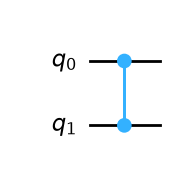

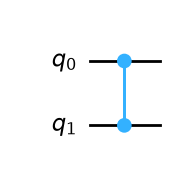

In [4]:
#creating own gate
circuit.cz(0,1)
circuit.to_gate()
circuit.draw(output = 'mpl')

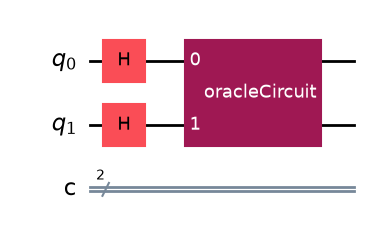

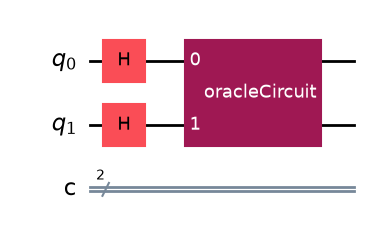

In [7]:
maincircuit = QuantumCircuit(2,2)
maincircuit.h([0,1])
maincircuit.append(circuit,[0,1])
maincircuit.draw(output = 'mpl')

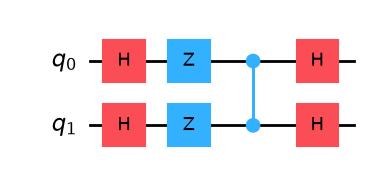

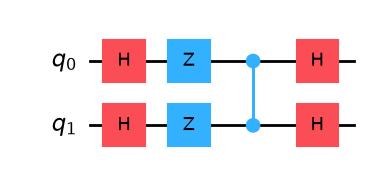

In [9]:
reflection = QuantumCircuit(2,name ="reflection")
reflection.h([0,1])
reflection.z([0,1])
reflection.cz(0,1)
reflection.h([0,1])
reflection.to_gate()
reflection.draw(output = 'mpl')

In [10]:
maincircuit.append(reflection,[0,1])

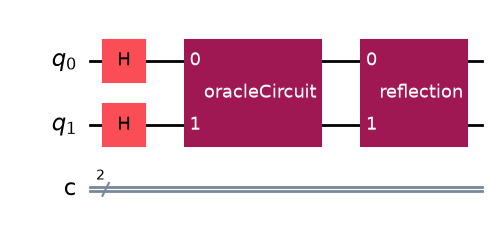

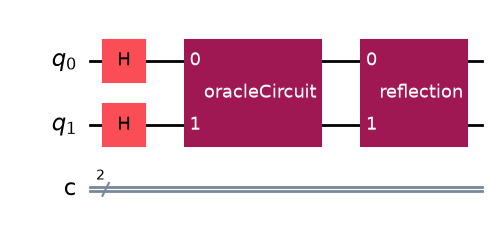

In [12]:
maincircuit.draw(output = 'mpl')

In [13]:
maincircuit.measure([0,1],[0,1])


In [14]:
from qiskit_ibm_runtime import QiskitRuntimeService
service = QiskitRuntimeService()
backends = service.backends()
for backend in backends:
    print(backend.name)
for backend in service.backends():
    status = backend.status()

    print("Backend:", backend.name)
    print("Operational:", status.operational)
    print("Pending jobs:", status.pending_jobs)


qiskit_runtime_service.__init__:WARNING:2026-10-30 16:26:00,787: Instance was not set at service instantiation. Free and trial plan instances will be prioritized. Based on the following filters: (tags: None, region: us-east, eu-de), and available plans: (open), the available account instances are: open-instance. If you need a specific instance set it explicitly either by using a saved account with a saved default instance or passing it in directly to QiskitRuntimeService(). Alternatively, pass instance='auto' or save it to your account for auto-selection without warning.
qiskit_runtime_service.backends:WARNING:2026-10-30 16:26:00,789: Loading instance: open-instance, plan: open
qiskit_runtime_service.backends:WARNING:2026-10-30 16:26:02,754: Loading instance: open-instance, plan: open


ibm_fez
ibm_kingston
ibm_marrakesh
Backend: ibm_fez
Operational: True
Pending jobs: 0
Backend: ibm_kingston
Operational: True
Pending jobs: 271
Backend: ibm_marrakesh
Operational: True
Pending jobs: 0


In [18]:
quantum_computer = service.backend("ibm_marrakesh")
from qiskit import transpile
compiled_circuit = transpile(
    circuit,
    backend=quantum_computer,
    translation_method="translator"
)
from qiskit_ibm_runtime import SamplerV2 as Sampler
sampler = Sampler(mode=quantum_computer)
job = sampler.run([compiled_circuit], shots=1024)
print("Job ID:", job.job_id())
print("Status:", job.status())

qiskit_runtime_service.backends:WARNING:2026-10-30 16:26:51,287: Using instance: open-instance, plan: open
/var/folders/kf/jd5w__vs3kg4vxwlhcczgzsm0000gn/T/ipykernel_40720/3351806976.py:9: DeprecationWarning: The SamplerV2 class is deprecated as of qiskit-ibm-runtime 0.50.0 and will be removed no sooner than 3 months after the release date. `qiskit_ibm_runtime.executor_sampler.Sampler` provides a new Sampler implementation that runs all the pre- and post-processing in the client side. The top-level `qiskit_ibm_runtime.Sampler` import will be updated to point to the client-side sampler in an upcoming release, with the legacy Sampler being available until the deprecation is completed.
  sampler = Sampler(mode=quantum_computer)


Job ID: dbi7ftg1h92s7382u030
Status: QUEUED


In [19]:
print("Status:", job.status())

Status: ERROR


In [20]:
try:
    result = job.result()
    print(result)
except Exception as e:
    print("Execution failed:")
    print(repr(e))

Execution failed:
RuntimeJobFailureError("Unable to retrieve job result. Error code 1515; Failed to execute program: 'Circuits without measurements are not allowed for this program.All your circuits must contain measurements. -- For information about the correct primitive input, see [Get started with primitives.](https://quantum.cloud.ibm.com/docs/guides/get-started-with-primitives) -- https://ibm.biz/error_codes#1515")


In [25]:
circuit.measure_all()
quantum_computer = service.backend("ibm_marrakesh")

from qiskit import transpile

compiled_circuit = transpile(
    maincircuit,
    backend=quantum_computer,
    translation_method="translator"
)

from qiskit_ibm_runtime import SamplerV2 as Sampler

sampler = Sampler(mode=quantum_computer)

job = sampler.run([compiled_circuit], shots=1024)

print("Job ID:", job.job_id())
print("Status:", job.status())

qiskit_runtime_service.backends:WARNING:2026-10-30 16:34:54,049: Using instance: open-instance, plan: open
/var/folders/kf/jd5w__vs3kg4vxwlhcczgzsm0000gn/T/ipykernel_40720/2662931663.py:14: DeprecationWarning: The SamplerV2 class is deprecated as of qiskit-ibm-runtime 0.50.0 and will be removed no sooner than 3 months after the release date. `qiskit_ibm_runtime.executor_sampler.Sampler` provides a new Sampler implementation that runs all the pre- and post-processing in the client side. The top-level `qiskit_ibm_runtime.Sampler` import will be updated to point to the client-side sampler in an upcoming release, with the legacy Sampler being available until the deprecation is completed.
  sampler = Sampler(mode=quantum_computer)


Job ID: dbi7jmene4hc73be2f50
Status: QUEUED


In [27]:
print("Status:", job.status())

Status: DONE


In [28]:
result = job.result()

counts = result[0].data.c.get_counts()

print(counts)

{'11': 996, '10': 15, '01': 11, '00': 2}


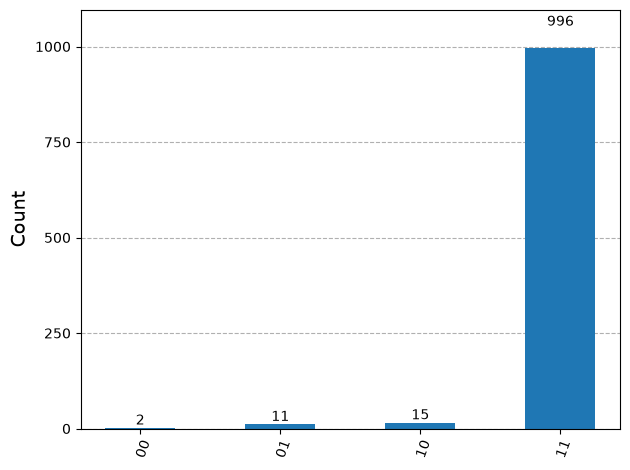

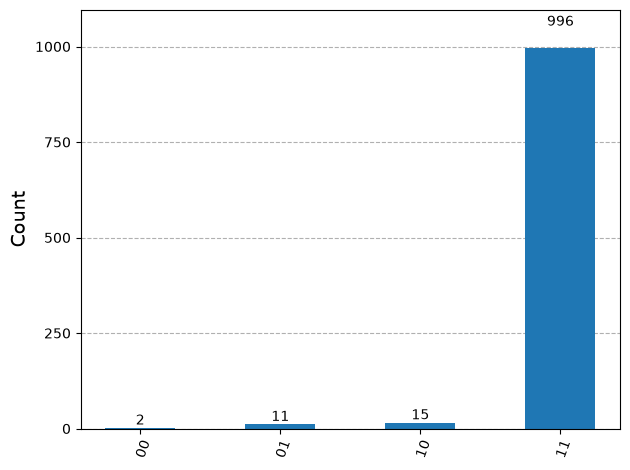

In [29]:
plot_histogram(counts)